# HW3 · Notebook 1: фіксований спліт, EDA, TF-IDF бейзлайн

Що робить цей ноутбук:
1. Робить **фіксовану** підвибірку train/val і зберігає її у `split.csv`, щоб усі наступні моделі порівнювалися на тому самому val.
2. EDA: баланс класів за мовою і доменом, довжини текстів, приклади, чим відрізняється fusion.
3. Бейзлайн: TF-IDF (слова + символи) → Logistic Regression / LinearSVC, невеликий пошук параметрів, per-class метрики, confusion matrix.
4. Перший сабміт + збереження ймовірностей для майбутнього ансамблю.

In [1]:
import os, glob, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from scipy.sparse import hstack

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 80)

# шукаємо файли змагання автоматично
train_path = glob.glob('/kaggle/input/**/train.csv', recursive=True) or ['data/train.csv']
DATA_DIR = os.path.dirname(train_path[0])
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else 'out'
os.makedirs(OUT_DIR, exist_ok=True)

train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
sample_sub = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')
LABELS = ['human', 'ai', 'fusion']
print(DATA_DIR, train.shape, test.shape)

/kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026 (272352, 5) (25000, 4)


## 1. Фіксований спліт

Беремо 40k текстів (умова каже, що 20–50k достатньо) і ділимо 80/20 на train/val.
Стратифікуємо за **label + lang**, щоб пропорції класів і мов у val були такі самі, як у повному train.
Індекси зберігаємо у файл, і всі наступні ноутбуки (трансформер, експерименти) читають саме його.

In [2]:
SAMPLE_SIZE = 40_000
strat = train['label'] + '_' + train['lang']
sample, _ = train_test_split(train, train_size=SAMPLE_SIZE, stratify=strat, random_state=SEED)
tr, val = train_test_split(sample, test_size=0.2, stratify=sample['label'] + '_' + sample['lang'],
                           random_state=SEED)

split = pd.concat([tr[['id']].assign(split='train'), val[['id']].assign(split='val')])
split.to_csv(f'{OUT_DIR}/split.csv', index=False)
print('train:', len(tr), '| val:', len(val))
print(val['label'].value_counts(normalize=True).round(3))

train: 32000 | val: 8000
label
ai        0.448
fusion    0.307
human     0.245
Name: proportion, dtype: float64


## 2. EDA
### 2.1 Баланс класів: загалом, за мовою, за доменом

label
ai        0.448
fusion    0.307
human     0.245
Name: proportion, dtype: float64 

Мови в train:
lang
en-EN    219581
de-DE     52771
Name: count, dtype: int64 

Мови в test:
lang
en-EN    21317
de-DE     3683
Name: count, dtype: int64


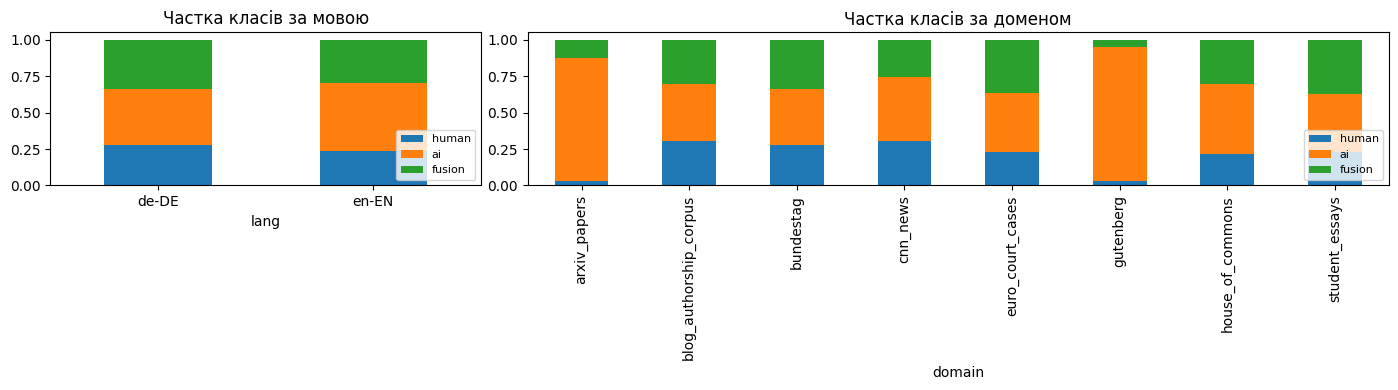

In [3]:
print(train['label'].value_counts(normalize=True).round(3), '\n')
print('Мови в train:'); print(train['lang'].value_counts(), '\n')
print('Мови в test:');  print(test['lang'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [1, 2]})
pd.crosstab(train['lang'], train['label'], normalize='index')[LABELS].plot.bar(stacked=True, ax=axes[0], rot=0)
axes[0].set_title('Частка класів за мовою')
pd.crosstab(train['domain'], train['label'], normalize='index')[LABELS].plot.bar(stacked=True, ax=axes[1])
axes[1].set_title('Частка класів за доменом')
for ax in axes: ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
# скільки текстів кожного класу в кожному домені + чи є ті самі домени в test
dom = pd.crosstab(train['domain'], train['label'])[LABELS]
dom['total'] = dom.sum(axis=1)
dom['in_test'] = dom.index.map(test['domain'].value_counts()).fillna(0).astype(int)
dom.sort_values('total', ascending=False)

label,human,ai,fusion,total,in_test
domain,,,,,
student_essays,12506,21583,20017,54106,3976
bundestag,14479,19977,17887,52343,3581
cnn_news,13395,19488,11402,44285,4937
blog_authorship_corpus,12466,15684,12397,40547,4446
house_of_commons,6953,15298,9608,31859,2941
euro_court_cases,6277,11141,10160,27578,1591
arxiv_papers,407,12050,1833,14290,1683
gutenberg,247,6719,378,7344,1845


### 2.2 Довжини текстів

         mean    25%    50%    75%     max
label                                     
ai      493.0  287.0  465.0  657.0  2996.0
fusion  585.0  263.0  445.0  695.0  3000.0
human   578.0  262.0  481.0  740.0  2998.0


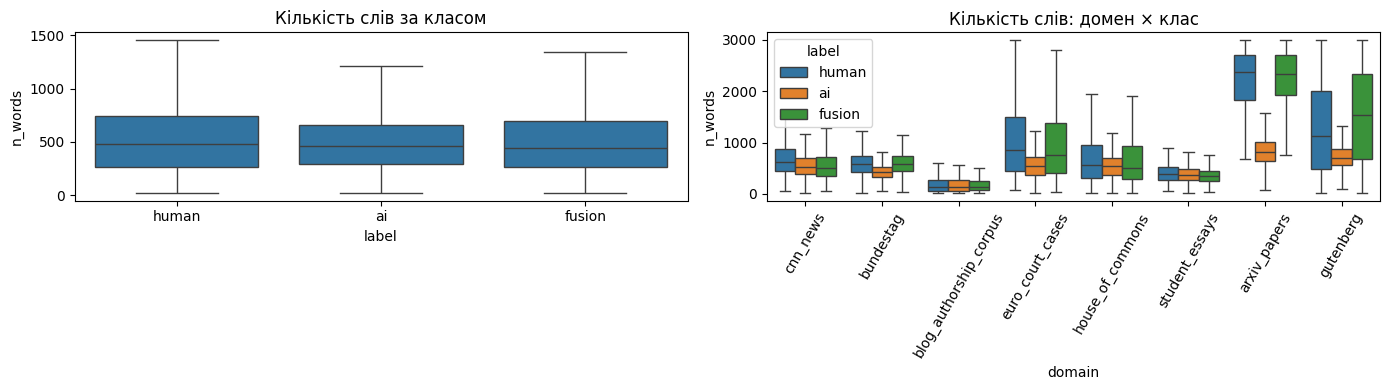

In [5]:
for d in (train, test):
    d['n_chars'] = d['text'].str.len()
    d['n_words'] = d['text'].str.split().str.len()

print(train.groupby('label')['n_words'].describe()[['mean', '25%', '50%', '75%', 'max']].round(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=train, x='label', y='n_words', order=LABELS, ax=axes[0], showfliers=False)
axes[0].set_title('Кількість слів за класом')
sns.boxplot(data=train, x='domain', y='n_words', hue='label', hue_order=LABELS, ax=axes[1], showfliers=False)
axes[1].tick_params(axis='x', rotation=60); axes[1].set_title('Кількість слів: домен × клас')
plt.tight_layout(); plt.show()

Скільки текстів не влазить у 512 токенів трансформера. Це вирішує, чи потрібна обробка довгих текстів.
Потрібен інтернет у ноутбуці (Settings → Internet on), щоб завантажити токенізатор.

In [6]:
try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained('xlm-roberta-base')
    s = train.sample(3000, random_state=SEED)
    s['n_tokens'] = [len(x) for x in tok(s['text'].tolist(), add_special_tokens=True)['input_ids']]
    print('Частка текстів > 512 токенів:', (s['n_tokens'] > 512).mean().round(3))
    print(s.groupby('label')['n_tokens'].median().rename('median tokens'))
    print((s['n_tokens'] / s['n_words']).groupby(s['lang']).mean().round(2).rename('tokens per word'))
except Exception as e:
    print('Токенізатор не завантажився (увімкни Internet):', e)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (722 > 512). Running this sequence through the model will result in indexing errors


Частка текстів > 512 токенів: 0.645
label
ai        697.5
fusion    618.5
human     647.0
Name: median tokens, dtype: float64
lang
de-DE    1.52
en-EN    1.43
Name: tokens per word, dtype: float64


### 2.3 Приклади кожного класу (перші 400 символів)

In [7]:
for lab in LABELS:
    row = train[(train['label'] == lab) & (train['lang'] == 'en-EN')].sample(1, random_state=1).iloc[0]
    print(f'=== {lab.upper()} | {row.domain} | {row.n_words} words ===')
    print(row.text[:400].replace('\n', ' '), '...\n')

=== HUMAN | cnn_news | 438 words ===
By . Associated Press . A New York hospital is banning electronic cigarettes after a patient on oxygen was burned by a fire that erupted while she was puffing on one of the devices. Syracuse Fire Department investigator Joe Galloway tells The Post-Standard the exact cause of last month's fire at St. Joseph's Hospital Health Center has not yet been determined. But he says the patient had a battery- ...

=== AI | blog_authorship_corpus | 316 words ===
I woke up this morning feeling like I was still on that island. It was just the dreamiest vacation, you know? Like stepping into a postcard, everything perfect. Crystal blue water lapped at white sand beaches – so soft, it felt like walking on powdered sugar. The air was warm and smelled of coconut and salt, with hints of hibiscus flowers blooming nearby. I spent my days just exploring the island. ...

=== FUSION | cnn_news | 494 words ===
By . James Chapman . PUBLISHED: . 18:43 EST, 19 July 2012 . | . U

### 2.4 Чим fusion відрізняється

Fusion — це людський текст, частину якого переписала LLM. Тому очікуємо, що за простими стилістичними ознаками
він буде **посередині** між human і ai, а не окремим "стилем". Перевіряємо на прості стилометричні ознаки.

In [8]:
def stylo(t):
    t = t[:5000]                      # довгі тексти (книги, суди) інакше рахуються дуже довго
    words = t.split()
    n_sents = max(len(re.findall(r'[.!?]+', t)), 1)
    n = max(len(t), 1)
    return {
        'avg_sent_len': len(words) / n_sents,
        'type_token_ratio': len(set(w.lower() for w in words[:300])) / max(min(len(words), 300), 1),
        'punct_ratio': len(re.findall(r'[,;:—–\-()"\']', t)) / n,
        'upper_ratio': len(re.findall(r'[A-ZÄÖÜ]', t)) / n,
        'digit_ratio': len(re.findall(r'\d', t)) / n,
        'newline_ratio': t.count('\n') / n,
    }

s = train.sample(6000, random_state=SEED)
feats = pd.DataFrame([stylo(t) for t in s['text']], index=s.index).join(s[['label', 'lang']])
feats.groupby(['lang', 'label']).median().round(4)

avg_sent_len  type_token_ratio  punct_ratio  upper_ratio  \
lang  label                                                              
de-DE ai           16.8571            0.6600       0.0124       0.0453   
      fusion       15.6897            0.6600       0.0138       0.0452   
      human        15.7407            0.6653       0.0147       0.0462   
en-EN ai           17.4706            0.6567       0.0143       0.0191   
      fusion       17.3617            0.6067       0.0121       0.0215   
      human        16.9000            0.5867       0.0129       0.0259   

              digit_ratio  newline_ratio  
lang  label                               
de-DE ai           0.0000            0.0  
      fusion       0.0013            0.0  
      human        0.0023            0.0  
en-EN ai           0.0005            0.0  
      fusion       0.0030            0.0  
      human        0.0039            0.0

**Висновки EDA:**
- **Баланс класів:** ai 44.8%, fusion 30.7%, human 24.5%. Класи незбалансовані, тому метрика macro-F1, а не accuracy.
- **Мови:** у train 80.6% EN / 19.4% DE, у test DE лише 14.7%. Спліт стратифікуємо за класом × мовою.
- **Домени:** `arxiv_papers` і `gutenberg` майже повністю ai; решта доменів змішані.
- **Довжини:** медіана ~450 слів / ~670 токенів XLM-R; 64.5% текстів довші за 512 токенів, тож для трансформера потрібна обробка довгих текстів (head+tail, chunks).
- **Fusion:** довжина як у human (в arxiv/gutenberg ai значно коротші), зберігає артефакти форматування джерела (`By . Associated Press .`); за стилометрією (TTR, частка цифр) лежить між human і ai. Глобальні статистики fusion від human не відділяють.

## 3. Бейзлайн: TF-IDF + лінійні моделі

- **word 1–2-грами** ловлять лексику ("delve", "furthermore", типові фрази LLM);
- **char_wb 3–5-грами** ловлять стиль і морфологію, працюють однаково для EN і DE.
- Векторизатори вчаться **тільки на train-частині** (fit на tr, transform на val/test), щоб не було leakage.
- Тексти обрізаємо до перших 5000 символів, щоб символьні n-грами вмістилися в пам'ять.

In [9]:
MAX_CHARS = 5000
clip = lambda s: s.str.slice(0, MAX_CHARS)

word_vec = TfidfVectorizer(analyzer='word', ngram_range=(1, 2), min_df=3, max_features=150_000,
                           sublinear_tf=True, lowercase=True)
char_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=5, max_features=300_000,
                           sublinear_tf=True, lowercase=False)

t0 = time.time()
X_tr = hstack([word_vec.fit_transform(clip(tr['text'])), char_vec.fit_transform(clip(tr['text']))]).tocsr()
X_val = hstack([word_vec.transform(clip(val['text'])), char_vec.transform(clip(val['text']))]).tocsr()
X_test = hstack([word_vec.transform(clip(test['text'])), char_vec.transform(clip(test['text']))]).tocsr()
y_tr, y_val = tr['label'].values, val['label'].values
print(X_tr.shape, f'{time.time() - t0:.0f}s')

(32000, 449245) 353s


Невеликий пошук параметрів: сила регуляризації C для двох моделей. Оцінка — macro-F1 на фіксованому val.

In [10]:
results = []
models = {}
for name, make in [('LogReg', lambda C: LogisticRegression(C=C, max_iter=2000)),
                   ('LinearSVC', lambda C: LinearSVC(C=C))]:
    for C in [0.3, 1, 3, 10] if name == 'LogReg' else [0.03, 0.1, 0.3, 1]:
        t0 = time.time()
        m = make(C).fit(X_tr, y_tr)
        f1 = f1_score(y_val, m.predict(X_val), average='macro')
        results.append({'model': name, 'C': C, 'macro_f1': round(f1, 4), 'sec': round(time.time() - t0)})
        models[(name, C)] = m
        print(results[-1])

res = pd.DataFrame(results).sort_values('macro_f1', ascending=False)
res

{'model': 'LogReg', 'C': 0.3, 'macro_f1': 0.832, 'sec': 131}
{'model': 'LogReg', 'C': 1, 'macro_f1': 0.8413, 'sec': 122}
{'model': 'LogReg', 'C': 3, 'macro_f1': 0.8411, 'sec': 250}
{'model': 'LogReg', 'C': 10, 'macro_f1': 0.8423, 'sec': 197}
{'model': 'LinearSVC', 'C': 0.03, 'macro_f1': 0.7992, 'sec': 21}
{'model': 'LinearSVC', 'C': 0.1, 'macro_f1': 0.8216, 'sec': 19}
{'model': 'LinearSVC', 'C': 0.3, 'macro_f1': 0.8251, 'sec': 26}
{'model': 'LinearSVC', 'C': 1, 'macro_f1': 0.8212, 'sec': 47}


,model,C,macro_f1,sec
3,LogReg,10.00,0.8423,197
1,LogReg,1.00,0.8413,122
2,LogReg,3.00,0.8411,250
0,LogReg,0.30,0.8320,131
6,LinearSVC,0.30,0.8251,26
5,LinearSVC,0.10,0.8216,19
7,LinearSVC,1.00,0.8212,47
4,LinearSVC,0.03,0.7992,21


Найкраща модель: ('LogReg', np.float64(10.0))
              precision    recall  f1-score   support

       human      0.737     0.786     0.761      1960
          ai      0.977     0.987     0.982      3581
      fusion      0.813     0.757     0.784      2459

    accuracy                          0.867      8000
   macro avg      0.842     0.844     0.842      8000
weighted avg      0.868     0.867     0.867      8000



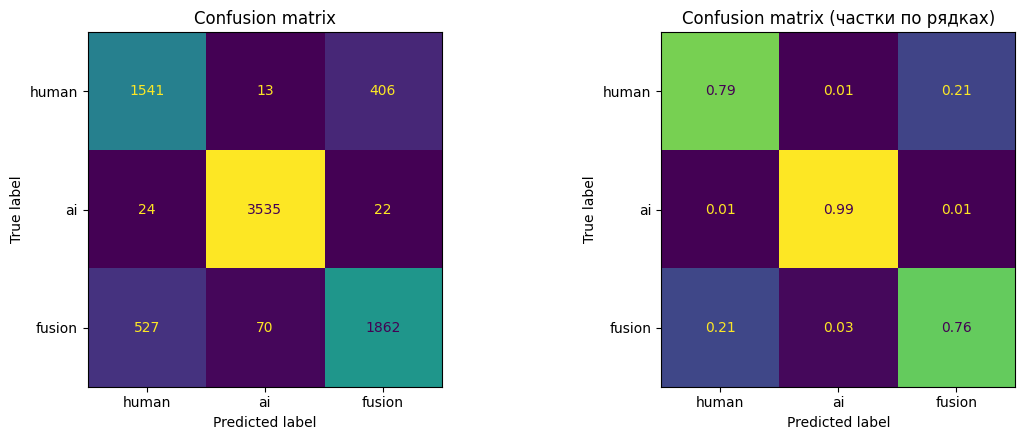

en-EN 0.8316
de-DE 0.8815


In [11]:
best_key = tuple(res.iloc[0][['model', 'C']])
best = models[best_key]
pred_val = best.predict(X_val)
print('Найкраща модель:', best_key)
print(classification_report(y_val, pred_val, labels=LABELS, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, norm in zip(axes, [None, 'true']):
    ConfusionMatrixDisplay(confusion_matrix(y_val, pred_val, labels=LABELS, normalize=norm),
                           display_labels=LABELS).plot(ax=ax, colorbar=False,
                                                       values_format='d' if norm is None else '.2f')
    ax.set_title('Confusion matrix' + (' (частки по рядках)' if norm else ''))
plt.tight_layout(); plt.show()

# macro-F1 окремо для кожної мови
for lang in val['lang'].unique():
    m = (val['lang'] == lang).values
    print(lang, round(f1_score(y_val[m], pred_val[m], average='macro'), 4))

## 4. Сабміт + збереження ймовірностей

Ймовірності LogReg на val і test зберігаємо, щоб пізніше зробити ансамбль з трансформером
і підібрати поріг для fusion.

In [12]:
best_lr = max(((k, v) for k, v in models.items() if k[0] == 'LogReg'),
              key=lambda kv: res.set_index(['model', 'C']).loc[kv[0], 'macro_f1'])[1]
order = [list(best_lr.classes_).index(l) for l in LABELS]          # колонки в порядку human, ai, fusion
np.save(f'{OUT_DIR}/tfidf_lr_val_proba.npy', best_lr.predict_proba(X_val)[:, order])
np.save(f'{OUT_DIR}/tfidf_lr_test_proba.npy', best_lr.predict_proba(X_test)[:, order])

sub = pd.DataFrame({'id': test['id'], 'label': best.predict(X_test)})
sub = sample_sub[['id']].merge(sub, on='id', how='left')            # порядок як у sample_submission
assert len(sub) == len(sample_sub) and sub['label'].notna().all() and sub['id'].is_unique
assert set(sub['label']) <= set(LABELS)
sub.to_csv(f'{OUT_DIR}/submission_tfidf.csv', index=False)
print(sub['label'].value_counts(normalize=True).round(3))

label
ai        0.520
human     0.264
fusion    0.217
Name: proportion, dtype: float64


## 5. (Бонус xAI) На що спирається бейзлайн

Найбільші коефіцієнти LogReg для кожного класу: які n-грами найсильніше тягнуть текст у цей клас.

In [13]:
feat_names = np.concatenate([['w:' + f for f in word_vec.get_feature_names_out()],
                             ['c:' + f for f in char_vec.get_feature_names_out()]])
for i, cls in enumerate(best_lr.classes_):
    top = np.argsort(best_lr.coef_[i])[-15:][::-1]
    print(f'{cls:>7}:', ' | '.join(str(f) for f in feat_names[top]))

     ai: c:’s  | w:let | w:just | c:t?  | c:t’s  | c:t’s | c:n’t | w:like | c:n’t  | c:’t  | w:this | c:s!  | w:maybe | w:seriously | c:e! 
 fusion: c: '  | c: "  | c: .. | c: ... | w:and | c: ’  | w:know if | w:missing | c: .  | w:me know | c: U.  | c:U.  | c: S. | c: …  | c: S. 
  human: c:.'  | c:.’  | w:dank | w:of the | w:vielen dank | c: i  | w:vielen | w:urllink | w:in conclusion | w:that is | w:will | w:das ist | w:from the | w:cnn | w:auch
